<a href="https://colab.research.google.com/github/najwanovalina/03-09-2025/blob/main/nusantaramart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_csv('penjualan_nusantaramart.csv')

# 1. Eksplorasi Awal Data[cite: 4]
print("--- 5 Baris Pertama ---")
print(df.head())

print("\n--- Informasi Data & Missing Value ---")
print(df.info())

print("\n--- Ringkasan Statistik ---")
print(df.describe())

# 2. Rata-rata total pembelian per kategori produk[cite: 4]
rata_kategori = df.groupby('kategori_produk')['total'].mean().sort_values(ascending=False)
print("\n--- Rata-rata Total Pembelian per Kategori ---")
print(rata_kategori)

# 3. Perbandingan Mean dan Median Keseluruhan[cite: 3]
print("\nMean Total  :", df['total'].mean())
print("Median Total:", df['total'].median())

--- 5 Baris Pertama ---
   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  

--- Informasi Data & Missing Value ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 

/tmp/ipykernel_541/2576837344.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


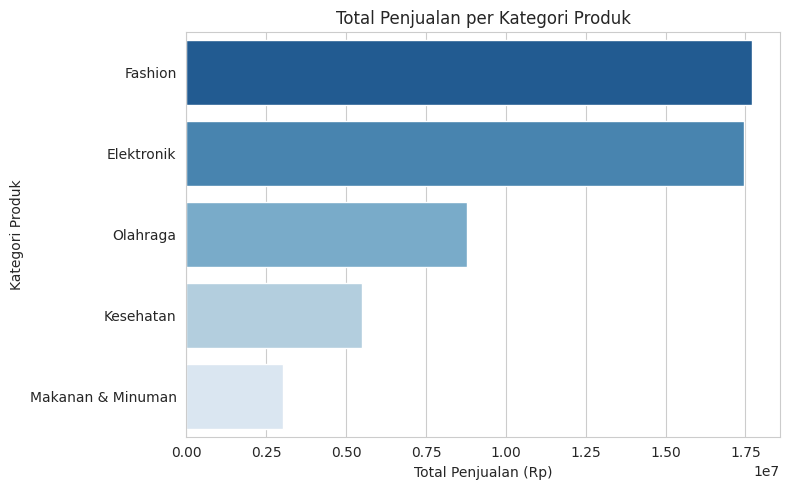

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

/tmp/ipykernel_541/2576837344.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


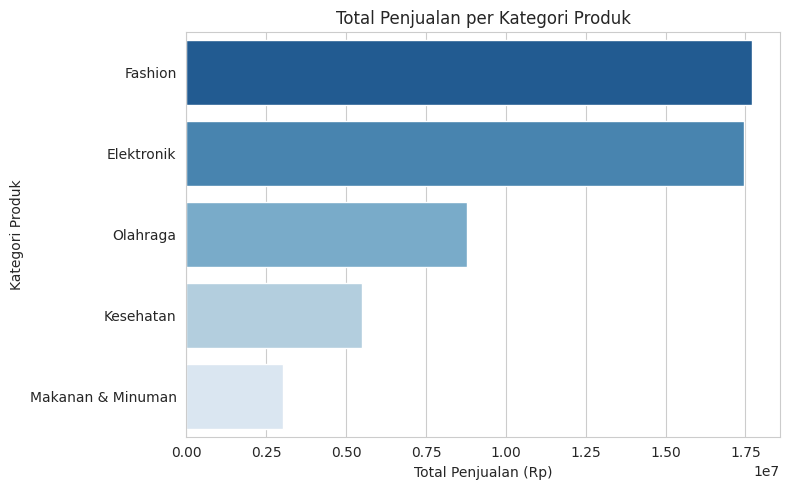

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# Menghitung total penjualan per kategori[cite: 4]
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)

# Membuat Bar Chart[cite: 4]
plt.figure(figsize=(8, 5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

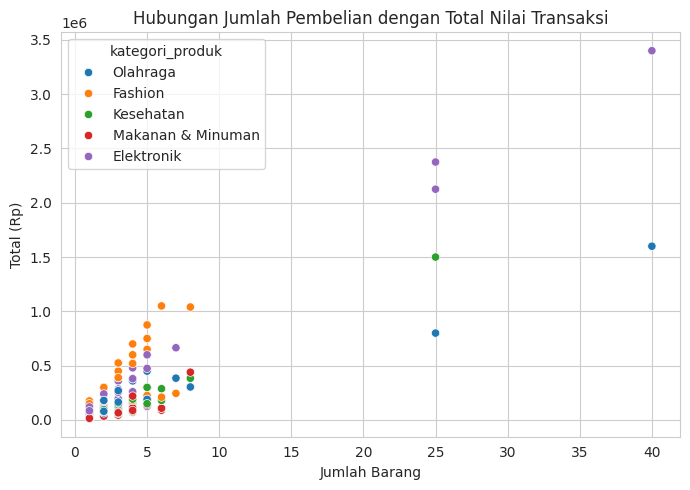

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

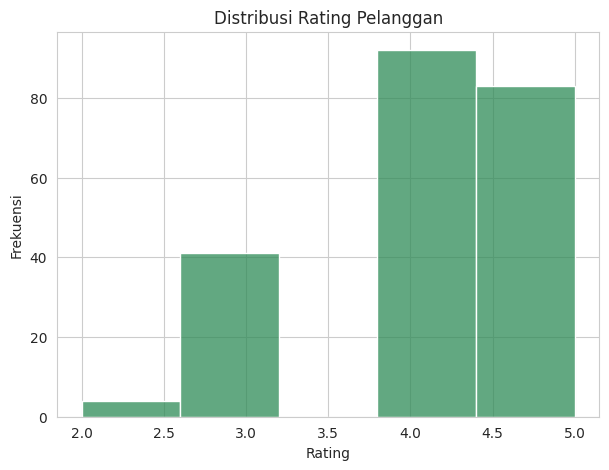

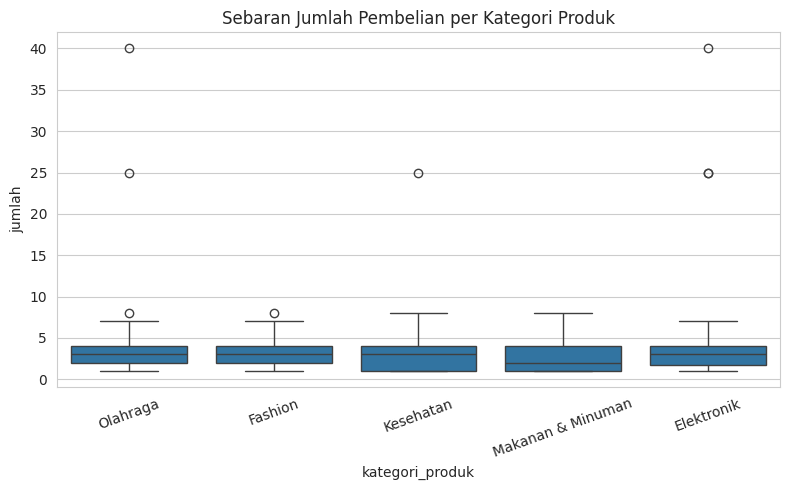

In [ ]:
plt.figure(figsize=(7, 5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

/tmp/ipykernel_541/3547719997.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0, 0], palette='Blues_r')
/tmp/ipykernel_541/3547719997.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1, 1], palette='Set2')


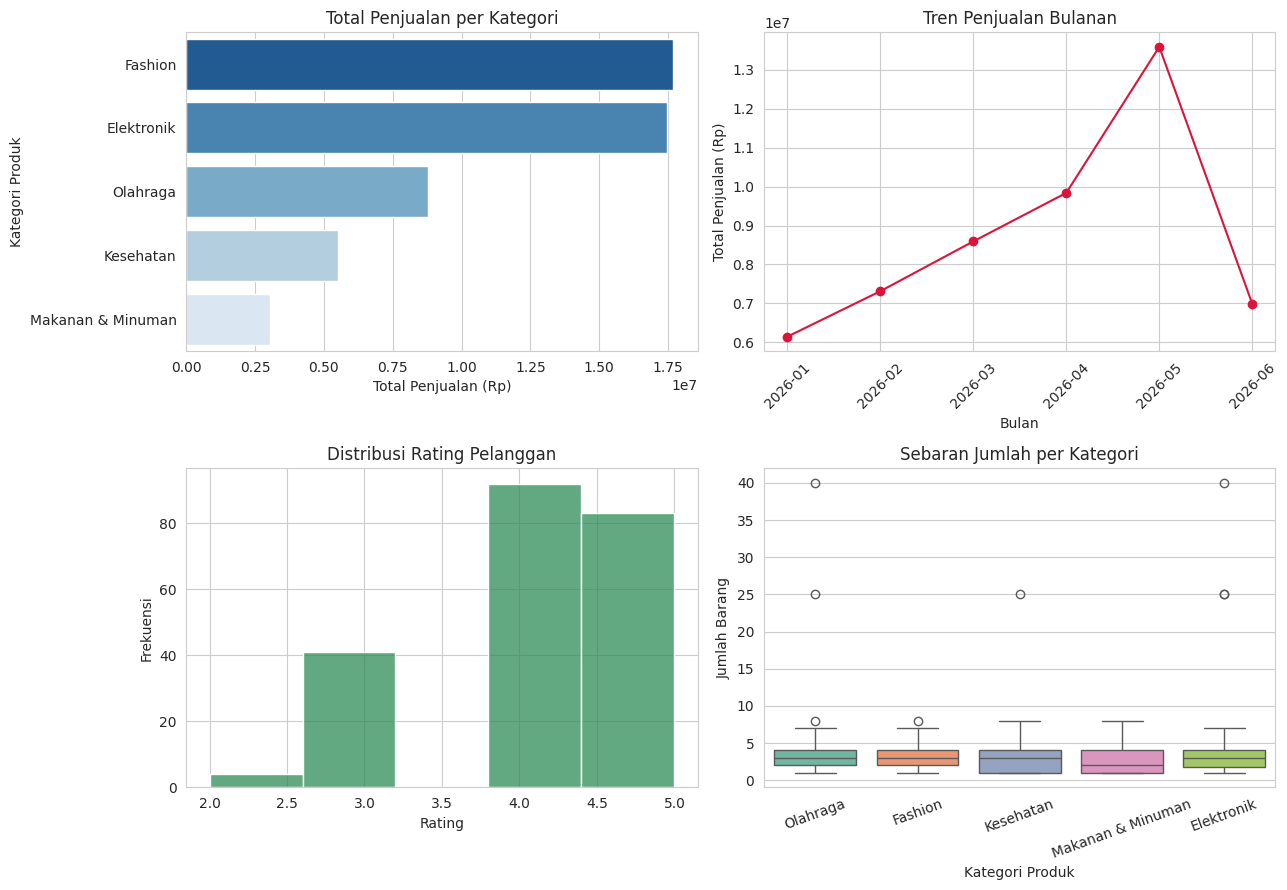

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('penjualan_nusantaramart.csv')

df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')

total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
tren_bulanan = df.groupby('bulan')['total'].sum()

sns.set_style('whitegrid')

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Total Penjualan per Kategori')
axes[0, 0].set_xlabel('Total Penjualan (Rp)')
axes[0, 0].set_ylabel('Kategori Produk')

axes[0, 1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
axes[0, 1].set_title('Tren Penjualan Bulanan')
axes[0, 1].set_xlabel('Bulan')
axes[0, 1].set_ylabel('Total Penjualan (Rp)')
axes[0, 1].tick_params(axis='x', rotation=45)

sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Distribusi Rating Pelanggan')
axes[1, 0].set_xlabel('Rating')
axes[1, 0].set_ylabel('Frekuensi')

sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Sebaran Jumlah per Kategori')
axes[1, 1].set_xlabel('Kategori Produk')
axes[1, 1].set_ylabel('Jumlah Barang')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

In [ ]:
print("=== LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART ===")
print(f"Total Penjualan    : Rp {df['total'].sum():,.0f}")
print(f"Rata-rata Transaksi: Rp {df['total'].mean():,.2f}")
print(f"Kategori Terlaris  : {df.groupby('kategori_produk')['total'].sum().idxmax()}")
print(f"Wilayah Teratas    : {df.groupby('wilayah')['total'].sum().idxmax()}")
print(f"Rating Rata-rata   : {df['rating_pelanggan'].mean():.2f}/5")

=== LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART ===
Total Penjualan    : Rp 52,467,000
Rata-rata Transaksi: Rp 238,486.36
Kategori Terlaris  : Fashion
Wilayah Teratas    : Surabaya
Rating Rata-rata   : 4.15/5


1. Rata-rata tertinggi = Elektronik (Rp363rb). Data miring kanan karena ada transaksi grosir (Mean Rp238rb vs Median Rp125rb). Missing value = Tidak ada (semua 220 baris terisi)
2. Penjualan tertinggi = Fashion (Rp17,6Jt) & Elektronik (Rp17,4Jt). Terendah = Makanan & Minuman (Rp3Jt). Rekomendasi: Amankan stok Fashion/Elektronik & buat promo bundling makanan
3. Puncak penjualan = Mei 2026 (Rp13,5Jt). Pola = Naik berturut-turut dari Jan–Mei, lalu turun di Juni

4. Hubungan barang dan total bernilai positif, dengan outlier (25–40 unit) pada Elektronik, Olahraga, dan Kesehatan
5. Rating pelanggan cenderung tinggi (rata-rata 4,15/5), sedangkan outlier pada boxplot disebabkan oleh transaksi borongan reseller
6. Dashboard mempermudah pemantauan data secara cepat dalam satu layar untuk dasar keputusan pengamanan stok dan paket grosir

Project:Omzet Rp52,467 Jt didominasi Fashion & Elektronik dengan puncak penjualan di Mei 2026, sehingga direkomendasikan penambahan stok April-Mei, pembuatan skema harga reseller, dan promo bundling Makanan & Minuman

